In [1]:
from Preprocessing import * 

In [2]:
genre_all_df = pd.read_csv('GenreAll.csv', sep=',')
target_column = " genre"

processing_genre_all = Preprocessing(genre_all_df, target_column)
processing_genre_all.run()
X_train, X_test, y_train, y_test = processing_genre_all.get_data()
#g_train, g_test = processing_genre_all.get_groups()
#meta_train, meta_test = processing_genre_all.get_meta()

=== Cleaning ===
Rows without target removed: 0
Duplicated rows removed: 13
Final shape: (980, 241)

X: (980, 240) | y: (980,)

=== Train / test split (80% / 20%) ===
Train: (784, 240) | Test: (196, 240)

Class proportions (train vs test):
       train   test
genre              
blu    0.102  0.102
cla    0.094  0.097
cou    0.102  0.102
dis    0.101  0.102
hip    0.101  0.097
jaz    0.102  0.102
met    0.094  0.097
pop    0.101  0.097
reg    0.101  0.102
roc    0.102  0.102

=== Categorical encoding ===
highlevel_speech_music_value: 2 categories
highlevel_voice_instrumental_value: 2 categories
tonal_key_mode_value: 2 categories
Features after encoding: 243

=== Constant columns removed (2) ===
['spectral_barkbands_25_dvar', 'spectral_barkbands_25_var']

=== Target encoding ===
0 -> blu
1 -> cla
2 -> cou
3 -> dis
4 -> hip
5 -> jaz
6 -> met
7 -> pop
8 -> reg
9 -> roc


In [3]:
"""
Combinatoria modelo x selector para Models.grid_search().

Cada modelo recibe una LISTA de diccionarios, uno por selector. No se puede
meter todo en un único diccionario porque cada selector tiene sus propios
hiperparámetros:

    anova / mutual_info .... selector__k
    pca_var ................ selector__n_components   (fracción de varianza)
    rf (importancia) ....... selector__max_features
    l1_logistic ............ selector__estimator__C
    correlation ............ selector__threshold
    lda / passthrough ...... (sin hiperparámetros)

Uso:
    models.build_models()                  # nombres = solo el nombre del modelo
    grids = build_param_grids(models.fs)
    print_grid_sizes(grids)

    for name, grid in grids.items():
        best, summary = models.grid_search(name, grid, nested=False, set_best=False)
        print(name); print(best_per_selector(summary))
"""

import pandas as pd

from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, SelectFromModel
from sklearn.model_selection import ParameterGrid

from FeatureSelection import *


# =====================================================================
# Hiperparámetros de cada modelo (sin selector)
# =====================================================================
MODEL_GRIDS = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10],
        "model__solver": ["lbfgs"],
        "model__class_weight": [None, "balanced"],
    },
    "KNN": {
        "model__n_neighbors": [3, 5, 7, 9, 13],
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2],
    },
    "Decision Tree": {
        "model__max_depth": [None, 5, 10, 20],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 5],
        "model__criterion": ["gini", "entropy"],
    },
    "ANN (MLP)": {
        "model__hidden_layer_sizes": [(64,), (128,), (128, 64)],
        "model__activation": ["relu", "tanh"],
        "model__alpha": [0.0001, 0.001, 0.01],
        "model__learning_rate_init": [0.0001, 0.001],
    },
    "Random Forest": {
        "model__n_estimators": [100, 300, 500],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_leaf": [1, 2, 5],
        "model__max_features": ["sqrt", 0.5],
    },
    "Extra Trees": {
        "model__n_estimators": [100, 300, 500],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_leaf": [1, 2, 5],
        "model__max_features": ["sqrt", 0.5],
    },
    "Gradient Boosting": {
        "model__n_estimators": [100, 200],
        "model__learning_rate": [0.01, 0.05, 0.1],
        "model__max_depth": [2, 3, 5],
        "model__subsample": [0.8, 1.0],
    },
    "AdaBoost": {
        "model__n_estimators": [50, 100, 200],
        "model__learning_rate": [0.01, 0.1, 0.5, 1.0],
        "model__estimator__max_depth": [1, 2, 3],
    },
    "Voting Ensemble": {
        "model__voting": ["soft", "hard"],
        "model__weights": [None, [2, 1, 1], [1, 2, 1]],
    },
}


# =====================================================================
# Espacio de búsqueda de cada selector
# =====================================================================
def selector_spaces(fs, k_values=(30, 50, 100)):
    k = list(k_values)
    return {
        "none": {"selector": ["passthrough"]},
        "correlation": {
            "selector": [fs.make("correlation")],
            "selector__threshold": [0.85, 0.95],
        },
        "anova": {"selector": [fs.make("anova")], "selector__k": k},
        "mutual_info": {"selector": [fs.make("mutual_info")], "selector__k": k},
        "pca_var": {
            "selector": [fs.make("pca_var", 0.95)],
            "selector__n_components": [0.90, 0.95, 0.99],
        },
        "lda": {"selector": [fs.make("lda")]},
        "l1_logistic": {
            "selector": [fs.make("l1_logistic")],
            "selector__estimator__C": [0.05, 0.1, 0.5],
        },
        "rf": {"selector": [fs.make("rf")], "selector__max_features": k},
    }


def build_param_grids(fs, model_grids=None, k_values=(30, 50, 100), exclude=None):
    """
    {nombre de modelo: [dict por selector]} listo para models.grid_search().

    exclude: {"Random Forest": ["pca_var", "lda"]} para saltarte combinaciones.
             Por defecto no se excluye nada (todos los selectores en todos los modelos).
    """

    model_grids = MODEL_GRIDS if model_grids is None else model_grids
    exclude = exclude or {}
    spaces = selector_spaces(fs, k_values)

    grids = {}
    for model, mgrid in model_grids.items():
        skip = set(exclude.get(model, ()))
        grids[model] = [
            {**space, **mgrid} for sel, space in spaces.items() if sel not in skip
        ]
    return grids


# =====================================================================
# Coste y resumen
# =====================================================================
def print_grid_sizes(grids, inner_splits=5, outer_splits=10):
    """Nº de combinaciones y de ajustes (fits) por modelo y en total."""
    rows = []
    for name, grid in grids.items():
        n = len(ParameterGrid(grid))
        rows.append({
            "Model": name,
            "Combinaciones": n,
            "Fits (nested=False)": n * inner_splits,
            "Fits (nested=True)": n * inner_splits * (outer_splits + 1),
        })
    df = pd.DataFrame(rows)
    total = df.drop(columns="Model").sum()
    df.loc[len(df)] = ["TOTAL", *total.values]
    print(df.to_string(index=False))
    return df


def selector_label(sel):
    if isinstance(sel, str):
        return "Sin selección"
    if isinstance(sel, SelectKBest):
        return "ANOVA"
    if isinstance(sel, FilterRanker):
        return "Info mutua"
    if isinstance(sel, CorrelationFilter):
        return "Correlación"
    if isinstance(sel, PCA):
        return "PCA var"
    if isinstance(sel, LinearDiscriminantAnalysis):
        return "LDA"
    if isinstance(sel, SelectFromModel):
        return "RF importancia" if isinstance(sel.estimator, RandomForestClassifier) else "L1 logística"
    return type(sel).__name__


def best_per_selector(summary):
    """Mejor combinación de cada selector a partir del `summary` de grid_search()."""
    df = summary["cv_results"].copy()
    df["Selector"] = df["params"].map(lambda p: selector_label(p["selector"]))
    df["Params"] = df["params"].map(
        lambda p: {k: v for k, v in p.items() if k != "selector"}
    )
    best = (
        df.sort_values("mean_test_score", ascending=False)
        .groupby("Selector", sort=False)
        .head(1)
        .reset_index(drop=True)
    )
    return best[["Selector", "mean_test_score", "std_test_score", "Params"]]

In [4]:
from Models import Models   # o como se llame tu archivo
#from grid_all_selectors import build_param_grids, print_grid_sizes, best_per_selector

models = Models(
    X_train, y_train,
    n_splits=10,
    random_state=42,
    n_jobs=-1,
)
n = models.X.shape[1]                       # 58
k_values = [k for k in (10, 20, 30, 40) if k < n]

models.build_models()
grids = build_param_grids(models.fs, k_values=k_values)
print_grid_sizes(grids)

results = {}
for name, grid in grids.items():
    best, summary = models.grid_search(name, grid, nested=False, set_best=False)
    results[name] = summary
    print(name)
    print(best_per_selector(summary))

              Model  Combinaciones  Fits (nested=False)  Fits (nested=True)
Logistic Regression            176                  880                9680
                KNN            440                 2200               24200
      Decision Tree           1584                 7920               87120
          ANN (MLP)            792                 3960               43560
      Random Forest           1188                 5940               65340
        Extra Trees           1188                 5940               65340
  Gradient Boosting            792                 3960               43560
           AdaBoost            792                 3960               43560
    Voting Ensemble            132                  660                7260
              TOTAL           7084                35420              389620
Best parameters (full train): {'model__C': 0.1, 'model__class_weight': None, 'model__solver': 'lbfgs', 'selector': SelectFromModel(estimator=LogisticRegression(C=0.

KeyboardInterrupt: 

MEJOR COMBINACIÓN DE CADA MODELO (CV)
              Model       Selector  mean_test_score  std_test_score
Logistic Regression   L1 logística         0.811212        0.013296
                KNN            LDA         0.788298        0.030846
          ANN (MLP)  Sin selección         0.783203        0.024532
      Decision Tree RF importancia         0.640340        0.015694

MEJOR COMBINACIÓN DE CADA SELECTOR, DENTRO DE CADA MODELO (CV)

ANN (MLP)
      Selector  mean_test_score  std_test_score
 Sin selección           0.7832          0.0245
   Correlación           0.7832          0.0222
       PCA var           0.7807          0.0341
  L1 logística           0.7692          0.0223
           LDA           0.7424          0.0262
RF importancia           0.7397          0.0382
         ANOVA           0.7028          0.0247
    Info mutua           0.6620          0.0239

Decision Tree
      Selector  mean_test_score  std_test_score
RF importancia           0.6403          0.0157
   C

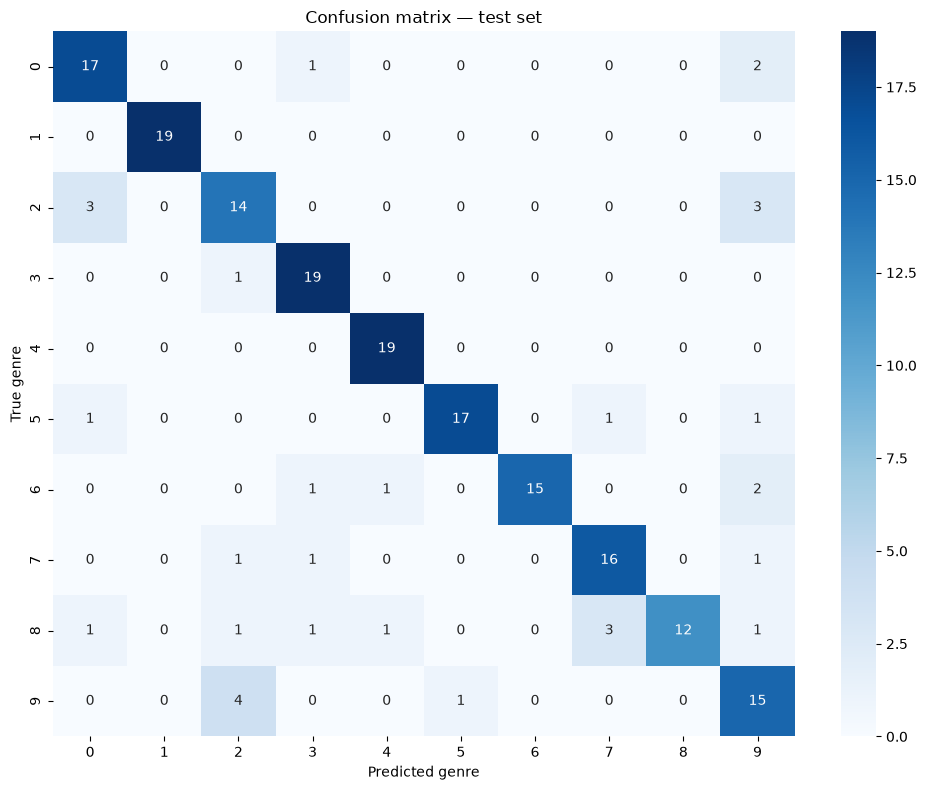

array([7, 3, 0, 9, 2, 0, 7, 9, 4, 9, 5, 5, 2, 4, 0, 3, 2, 7, 6, 9, 7, 3,
       1, 6, 0, 1, 2, 3, 4, 4, 2, 9, 3, 8, 7, 0, 6, 5, 5, 8, 3, 1, 7, 2,
       1, 5, 9, 3, 3, 0, 0, 5, 2, 1, 7, 4, 6, 4, 4, 0, 0, 6, 7, 3, 4, 0,
       3, 2, 7, 8, 9, 1, 3, 6, 0, 7, 6, 4, 8, 1, 0, 1, 2, 0, 6, 7, 5, 2,
       1, 9, 4, 1, 5, 3, 1, 3, 7, 9, 0, 5, 3, 9, 2, 0, 6, 9, 1, 6, 7, 1,
       4, 4, 9, 3, 8, 4, 3, 3, 2, 4, 9, 1, 5, 3, 1, 7, 2, 5, 2, 4, 1, 4,
       9, 2, 1, 9, 9, 9, 5, 2, 9, 2, 1, 7, 2, 4, 0, 0, 9, 8, 7, 0, 9, 9,
       1, 2, 8, 6, 7, 0, 9, 5, 8, 4, 3, 4, 2, 0, 5, 2, 4, 9, 3, 3, 0, 6,
       6, 3, 5, 0, 9, 6, 5, 7, 6, 8, 4, 9, 8, 5, 7, 7, 5, 3, 8, 8])

In [5]:
import os, re, joblib
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import accuracy_score, f1_score

os.makedirs("results/pipelines", exist_ok=True)

# ---------------------------------------------------------------
# 1) TODAS las combinaciones -> CSV
# ---------------------------------------------------------------
def tidy_cv(name, summary):
    cv = summary["cv_results"].reset_index(drop=True)
    params = pd.DataFrame(
        [{k: v for k, v in p.items() if k != "selector"} for p in cv["params"]]
    )
    head = pd.DataFrame({
        "Model": name,
        "Selector": cv["params"].map(lambda p: selector_label(p["selector"])),
    })
    return pd.concat(
        [head, cv[["mean_test_score", "std_test_score", "rank_test_score"]], params],
        axis=1,
    )

per_model = {n: tidy_cv(n, s) for n, s in results.items()}
for n, df in per_model.items():
    df.to_csv(f"results/cv_{re.sub(r'\W+', '_', n)}.csv", index=False)

all_cv = pd.concat(per_model.values(), ignore_index=True)
all_cv.to_csv("results/cv_all_combinations.csv", index=False)

# ---------------------------------------------------------------
# 2) Mejor combinación por modelo y por (modelo, selector)
# ---------------------------------------------------------------
ranked = all_cv.sort_values("mean_test_score", ascending=False)

best_per_model = ranked.groupby("Model", sort=False).head(1).reset_index(drop=True)
best_per_model_selector = (
    ranked.groupby(["Model", "Selector"], sort=False).head(1)
    .sort_values(["Model", "mean_test_score"], ascending=[True, False])
    .reset_index(drop=True)
)
best_per_model.to_csv("results/best_per_model.csv", index=False)
best_per_model_selector.to_csv("results/best_per_model_selector.csv", index=False)

print("MEJOR COMBINACIÓN DE CADA MODELO (CV)")
print(best_per_model[["Model", "Selector", "mean_test_score", "std_test_score"]]
      .to_string(index=False))

print("\nMEJOR COMBINACIÓN DE CADA SELECTOR, DENTRO DE CADA MODELO (CV)")
for model, g in best_per_model_selector.groupby("Model", sort=False):
    print(f"\n{model}")
    print(g[["Selector", "mean_test_score", "std_test_score"]]
          .to_string(index=False, float_format="{:.4f}".format))

# ---------------------------------------------------------------
# 3) Reentrenar el ganador de cada modelo con todo el train
#    (un solo fit por modelo, a partir de best_params)
# ---------------------------------------------------------------
tuned = {}
for name, s in results.items():
    pipe = clone(models.models[name]).set_params(**s["best_params"])
    pipe.fit(models.X, models.y)
    tuned[name] = pipe
    fname = re.sub(r"\W+", "_", name)
    joblib.dump(pipe, f"results/pipelines/{fname}.joblib")

# ---------------------------------------------------------------
# 4) Test: una sola vez, con el ganador de cada modelo
# ---------------------------------------------------------------
Xt = models._align(X_test)
rows = []
for _, r in best_per_model.iterrows():
    pred = tuned[r["Model"]].predict(Xt)
    rows.append({
        "Model": r["Model"],
        "Selector": r["Selector"],
        "CV Acc": r["mean_test_score"],
        "Test Acc": accuracy_score(y_test, pred),
        "Test F1": f1_score(y_test, pred, average="macro"),
    })
test_table = pd.DataFrame(rows).sort_values("CV Acc", ascending=False)
test_table.to_csv("results/test_best_per_model.csv", index=False)
print("\nTEST (ordenado por CV, no por test)")
print(test_table.to_string(index=False, float_format="{:.4f}".format))

# ---------------------------------------------------------------
# 5) Informe completo + matriz de confusión del elegido
# ---------------------------------------------------------------
elegido = best_per_model.loc[0, "Model"]         # el mejor por CV
models.best_model, models.best_model_name = tuned[elegido], f"{elegido} (tuned)"
models.evaluate_on_test(X_test, y_test)